# Assignment 4 — LoRA Fine-Tuning Comparison

The base model `Qwen/Qwen2.5-Coder-1.5B` has read a lot of code, but it was not trained to answer an instruction. This notebook teaches it that behavior with LoRA on the 374 MBPP training problems, then scores the same 50 test problems before and after.

The adapter is saved in the `lora_adapter` folder in this repo so it can be loaded again without training.


## Setup

The model is loaded in 4-bit with bitsandbytes. Every evaluation uses the same prompt, greedy decoding (`do_sample=False`), the same extraction rule, and the same test harness.


In [1]:
import ast
import json
import os
import re
import subprocess
import sys
import tempfile
import time

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

import matplotlib.pyplot as plt
import torch
from datasets import Dataset, load_dataset
from peft import (
    LoraConfig,
    PeftModel,
    TaskType,
    get_peft_model,
    prepare_model_for_kbit_training,
)
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    Trainer,
    TrainingArguments,
)

MODEL_NAME = "Qwen/Qwen2.5-Coder-1.5B"
ADAPTER_DIR = "lora_adapter"
RESULTS_DIR = "results"
MAX_LENGTH = 320
MAX_NEW_TOKENS = 512
TIMEOUT_SECONDS = 3
EVAL_COUNT = 50

# LoRA settings. Rank, alpha, dropout, target modules, epochs, and the
# effective batch size are the assignment's starting values.
# Learning rate is 1e-4 instead of 2e-4. At 2e-4 the loss fell, then jumped
# above 6, and the model stopped writing real functions. A short warmup
# (5% of steps) keeps the start from jumping.
LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj"]
EPOCHS = 3
LEARNING_RATE = 1e-4
WARMUP_STEPS = 0.05
BATCH_SIZE = 1
GRAD_ACCUM = 4  # effective batch size = 1 * 4 = 4

BUCKETS = ["no_function", "runs_fails", "passes"]
BUCKET_LABELS = {
    "no_function": "No function",
    "runs_fails": "Runs, fails tests",
    "passes": "Passes",
}


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

## Part A: Baseline

Prompt template, used for training and for both evaluations:

```
### Instruction:
{text}

### Response:
```

For each of the first 50 test problems I generate a completion with greedy decoding. Greedy decoding is deterministic, so a later change in the score comes from the adapter, not from random sampling.

**Extraction rule** (one rule, applied to every output, with no hand fixes):

1. If the text has a markdown code fence, take the inside of the first fence. If the fence is opened but never closed, take from the opening fence to the end.
2. If there is no fence, start at the first line that is a `def`, `import`, `from`, `class`, decorator, or assignment, and keep the rest of the text.
3. Delete lines from the bottom until the remaining text is valid Python. If nothing valid is left, there is no function.
4. If that Python does not contain a `def`, count it as **No function**.

**Harness:** run the extracted code, then the three asserts in `test_list`, in a subprocess with a 3 second timeout.

- **No function** — the rule found no function.
- **Runs, fails tests** — a function was extracted, but the program timed out, raised, or an assert failed.
- **Passes** — all three asserts passed.


In [2]:
def make_prompt(text):
    return f"### Instruction:\n{text}\n\n### Response:\n"


def _line_starts_code(line):
    stripped = line.strip()
    if stripped.startswith(("def ", "import ", "from ", "class ", "@")):
        return True
    return re.match(r"[A-Za-z_][A-Za-z0-9_]*\s*=", stripped) is not None


def _trim_to_valid_python(text):
    lines = text.splitlines()
    while lines and lines[-1].strip() == "":
        lines.pop()
    while lines:
        candidate = "\n".join(lines)
        try:
            ast.parse(candidate)
            return candidate
        except SyntaxError:
            lines.pop()
    return None


def extract_function(text):
    """Apply the single extraction rule. Return the code, or None."""
    if text is None or text.strip() == "":
        return None

    closed = re.search(
        r"```(?:python|py)?\s*\n(.*?)```",
        text,
        flags=re.DOTALL | re.IGNORECASE,
    )
    if closed:
        body = closed.group(1)
    else:
        opened = re.search(
            r"```(?:python|py)?\s*\n(.*)$",
            text,
            flags=re.DOTALL | re.IGNORECASE,
        )
        if opened:
            body = opened.group(1)
        else:
            lines = text.splitlines()
            start = None
            for index, line in enumerate(lines):
                if _line_starts_code(line):
                    start = index
                    break
            if start is None:
                return None
            body = "\n".join(lines[start:])

    body = _trim_to_valid_python(body)
    if body is None:
        return None
    if re.search(r"(?m)^\s*def\s+", body) is None:
        return None
    return body


def score_extraction(extracted, tests):
    """Run extracted code plus the three asserts. Return one bucket name."""
    if extracted is None:
        return "no_function"

    program = extracted + "\n\n" + "\n".join(tests) + "\n"
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, "solution.py")
        with open(path, "w", encoding="utf-8") as handle:
            handle.write(program)
        try:
            result = subprocess.run(
                [sys.executable, path],
                capture_output=True,
                text=True,
                timeout=TIMEOUT_SECONDS,
                cwd=tmp,
            )
        except subprocess.TimeoutExpired:
            return "runs_fails"
    if result.returncode == 0:
        return "passes"
    return "runs_fails"


def count_buckets(rows):
    counts = {name: 0 for name in BUCKETS}
    for row in rows:
        counts[row["bucket"]] += 1
    return counts


def print_counts(rows):
    counts = count_buckets(rows)
    for name in BUCKETS:
        print(f"{BUCKET_LABELS[name]}: {counts[name]}")
    print(f"Pass rate: {counts['passes']}/{len(rows)}")
    return counts


def generate_completion(prompt):
    device = next(model.parameters()).device
    inputs = tokenizer(prompt, return_tensors="pt")
    inputs = {key: value.to(device) for key, value in inputs.items()}
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
        )
    new_ids = output_ids[0][inputs["input_ids"].shape[1] :]
    return tokenizer.decode(new_ids, skip_special_tokens=True)


def evaluate(problems, save_path):
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    rows = []
    started = time.perf_counter()
    for index, problem in enumerate(problems):
        generation = generate_completion(make_prompt(problem["text"]))
        extracted = extract_function(generation)
        bucket = score_extraction(extracted, problem["test_list"])
        rows.append(
            {
                "task_id": int(problem["task_id"]),
                "text": problem["text"],
                "test_list": list(problem["test_list"]),
                "generation": generation,
                "extracted": extracted,
                "bucket": bucket,
            }
        )
        print(
            f"{index + 1:02d}/{len(problems)} task {problem['task_id']} -> {bucket}",
            flush=True,
        )
        with open(save_path, "w", encoding="utf-8") as handle:
            json.dump(rows, handle, indent=2)
    elapsed = time.perf_counter() - started
    print(f"evaluation finished in {elapsed / 60:.1f} minutes")
    print_counts(rows)
    return rows


In [3]:
try:
    ds = load_dataset("mbpp")
except Exception:
    # This datasets version rejects the short name "mbpp" because it has no
    # namespace. google-research-datasets/mbpp is the same full dataset.
    print("load_dataset('mbpp') did not work here.")
    print("Loading google-research-datasets/mbpp (the same full MBPP dataset).")
    ds = load_dataset("google-research-datasets/mbpp")

print({name: len(split) for name, split in ds.items()})
eval_problems = ds["test"].select(range(EVAL_COUNT))
print("evaluating test[:50], first task", eval_problems[0]["task_id"], "last task", eval_problems[-1]["task_id"])

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

quantization = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
)
device_map = "auto" if torch.cuda.is_available() else {"": "cpu"}
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=quantization,
    device_map=device_map,
)
model.eval()
print("loaded", MODEL_NAME, "in 4-bit on", device_map)


load_dataset('mbpp') did not work here.
Loading google-research-datasets/mbpp (the same full MBPP dataset).


{'train': 374, 'test': 500, 'validation': 90, 'prompt': 10}
evaluating test[:50], first task 11 last task 60


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

loaded Qwen/Qwen2.5-Coder-1.5B in 4-bit on {'': 'cpu'}


In [4]:
baseline_path = os.path.join(RESULTS_DIR, "baseline.json")
if os.path.isfile(baseline_path):
    with open(baseline_path, encoding="utf-8") as handle:
        baseline_rows = json.load(handle)
else:
    baseline_rows = None

if baseline_rows is not None and len(baseline_rows) == EVAL_COUNT:
    print("Loaded the saved baseline generations from", baseline_path)
    print_counts(baseline_rows)
else:
    baseline_rows = evaluate(eval_problems, baseline_path)
    print("saved", baseline_path)


Loaded the saved baseline generations from results/baseline.json
No function: 0
Runs, fails tests: 47
Passes: 3
Pass rate: 3/50


## Part B: Training data

Each of the 374 training problems becomes one prompt and one response. The prompt uses the same template as Part A. The response is the reference solution, followed by the end-of-text token so the model can learn where to stop.

**Loss masking.** The loss is computed on the response tokens only. The instruction tokens are labeled `-100`, which tells the trainer to ignore them. The model should learn to write the solution, not to copy the question.

**Truncation.** The maximum sequence length is 320 tokens. I picked 320 because the longest training example is shorter than that, so the cutoff should not throw away solutions. The cell below prints how many of the 374 examples are actually truncated.

The reference code in this dataset uses Windows newlines (`\r\n`). I convert those to normal newlines so the model learns ordinary Python.


In [5]:
def build_training_records(train_split):
    records = []
    truncated = 0
    prefix_mismatches = 0
    for row in train_split:
        prompt = make_prompt(row["text"])
        response = row["code"].replace("\r\n", "\n").replace("\r", "\n")
        if not response.endswith("\n"):
            response += "\n"
        response += tokenizer.eos_token
        prompt_ids = tokenizer(prompt, add_special_tokens=True)["input_ids"]
        full_ids = tokenizer(prompt + response, add_special_tokens=True)["input_ids"]
        if len(full_ids) > MAX_LENGTH:
            truncated += 1
            full_ids = full_ids[:MAX_LENGTH]
        mask_len = min(len(prompt_ids), len(full_ids))
        if full_ids[:mask_len] != prompt_ids[:mask_len]:
            prefix_mismatches += 1
        labels = list(full_ids)
        for index in range(mask_len):
            labels[index] = -100
        records.append(
            {
                "input_ids": list(full_ids),
                "attention_mask": [1] * len(full_ids),
                "labels": labels,
                "prompt": prompt,
                "response": response,
            }
        )
    return records, truncated, prefix_mismatches


training_records, truncated_count, prefix_mismatches = build_training_records(ds["train"])
print(f"training examples: {len(training_records)}")
print(f"max length: {MAX_LENGTH}")
print(f"truncated: {truncated_count} of {len(training_records)}")
print(f"prompt was not a token prefix (should be 0): {prefix_mismatches}")
print()
print("Loss is masked on the instruction. The two examples below are the full")
print("training text. Everything after '### Response:' is the response the model")
print("is trained to produce.")

for example_number in (1, 2):
    record = training_records[example_number - 1]
    print()
    print("=" * 60)
    print(f"FORMATTED EXAMPLE {example_number}")
    print("=" * 60)
    print(record["prompt"] + record["response"])

train_dataset = Dataset.from_list(
    [
        {
            "input_ids": record["input_ids"],
            "attention_mask": record["attention_mask"],
            "labels": record["labels"],
        }
        for record in training_records
    ]
)


training examples: 374
max length: 320
truncated: 0 of 374
prompt was not a token prefix (should be 0): 0

Loss is masked on the instruction. The two examples below are the full
training text. Everything after '### Response:' is the response the model
is trained to produce.

FORMATTED EXAMPLE 1
### Instruction:
Write a function to find the longest chain which can be formed from the given set of pairs.

### Response:
class Pair(object): 
	def __init__(self, a, b): 
		self.a = a 
		self.b = b 
def max_chain_length(arr, n): 
	max = 0
	mcl = [1 for i in range(n)] 
	for i in range(1, n): 
		for j in range(0, i): 
			if (arr[i].a > arr[j].b and
				mcl[i] < mcl[j] + 1): 
				mcl[i] = mcl[j] + 1
	for i in range(n): 
		if (max < mcl[i]): 
			max = mcl[i] 
	return max
<|endoftext|>

FORMATTED EXAMPLE 2
### Instruction:
Write a python function to find the first repeated character in a given string.

### Response:
def first_repeated_char(str1):
  for index,c in enumerate(str1):
    if str1[:index

## Part C: Fine-tune

LoRA is attached to the 4-bit base model.

I kept the assignment's starting values for rank (16), alpha (32), dropout (0.05), target modules (`q_proj`, `k_proj`, `v_proj`, `o_proj`), epochs (3), and effective batch size (4). The batch is 1, with gradient accumulation of 4, because that is easier on memory.

I changed the learning rate from 2e-4 to 1e-4, and I warm up for the first 5% of steps. At 2e-4 the loss dropped toward 0.9 and then jumped above 6. After that the model only repeated junk, so every fine-tuned output failed the extraction rule. 1e-4 with a short warmup keeps the loss going down.

If `lora_adapter` is already saved, this cell loads it instead of training again.


In [6]:
def collate(features):
    width = max(len(item["input_ids"]) for item in features)

    def padded(key, fill):
        rows = []
        for item in features:
            row = list(item[key])
            row.extend([fill] * (width - len(row)))
            rows.append(row)
        return torch.tensor(rows, dtype=torch.long)

    return {
        "input_ids": padded("input_ids", tokenizer.pad_token_id),
        "attention_mask": padded("attention_mask", 0),
        "labels": padded("labels", -100),
    }


log_path = os.path.join(ADAPTER_DIR, "training_log.json")
adapter_file = os.path.join(ADAPTER_DIR, "adapter_config.json")

if os.path.isfile(adapter_file) and os.path.isfile(log_path):
    print("Saved adapter found. Loading it instead of training.")
    model = PeftModel.from_pretrained(model, ADAPTER_DIR)
    with open(log_path, encoding="utf-8") as handle:
        training_log = json.load(handle)
else:
    torch.manual_seed(42)
    model = prepare_model_for_kbit_training(
        model,
        gradient_checkpointing_kwargs={"use_reentrant": False},
    )
    lora_config = LoraConfig(
        r=LORA_R,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        target_modules=TARGET_MODULES,
        bias="none",
        task_type=TaskType.CAUSAL_LM,
    )
    model = get_peft_model(model, lora_config)
    model.print_trainable_parameters()
    trainable, total = model.get_nb_trainable_parameters()
    print(f"trainable params: {trainable:,}")
    print(f"total params: {total:,}")
    print(f"trainable percent: {100 * trainable / total:.4f}%")

    training_args = TrainingArguments(
        output_dir="/tmp/lora_mbpp_trainer",
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRAD_ACCUM,
        learning_rate=LEARNING_RATE,
        warmup_steps=WARMUP_STEPS,
        logging_steps=10,
        save_strategy="no",
        report_to="none",
        fp16=False,
        bf16=torch.cuda.is_available(),
        dataloader_pin_memory=False,
        remove_unused_columns=False,
        use_cpu=not torch.cuda.is_available(),
        seed=42,
    )
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        data_collator=collate,
    )
    started = time.perf_counter()
    trainer.train()
    wall_seconds = time.perf_counter() - started

    os.makedirs(ADAPTER_DIR, exist_ok=True)
    model.save_pretrained(ADAPTER_DIR)
    loss_points = []
    for entry in trainer.state.log_history:
        if "loss" in entry:
            loss_points.append(
                {
                    "step": int(entry["step"]),
                    "loss": float(entry["loss"]),
                    "epoch": float(entry.get("epoch", 0.0)),
                }
            )
    training_log = {
        "wall_clock_seconds": wall_seconds,
        "trainable_params": trainable,
        "total_params": total,
        "loss_points": loss_points,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "warmup_steps": WARMUP_STEPS,
        "lora_r": LORA_R,
        "lora_alpha": LORA_ALPHA,
        "lora_dropout": LORA_DROPOUT,
        "target_modules": TARGET_MODULES,
        "per_device_batch_size": BATCH_SIZE,
        "gradient_accumulation_steps": GRAD_ACCUM,
        "max_length": MAX_LENGTH,
    }
    with open(log_path, "w", encoding="utf-8") as handle:
        json.dump(training_log, handle, indent=2)
    print(f"saved adapter to {ADAPTER_DIR}")

print(f"trainable params: {training_log['trainable_params']:,}")
print(f"total params: {training_log['total_params']:,}")
minutes = training_log["wall_clock_seconds"] / 60
print(f"wall clock training time: {training_log['wall_clock_seconds']:.1f} seconds ({minutes:.1f} minutes)")


trainable params: 4,358,144 || all params: 1,548,072,448 || trainable%: 0.2815
trainable params: 4,358,144
total params: 1,548,072,448
trainable percent: 0.2815%


Step,Training Loss
10,1.202464
20,0.839455
30,0.725523
40,0.680470
50,0.719804
60,0.698253
70,0.666292
80,0.734824
90,0.658134
100,0.685797


saved adapter to lora_adapter
trainable params: 4,358,144
total params: 1,548,072,448
wall clock training time: 1260.7 seconds (21.0 minutes)


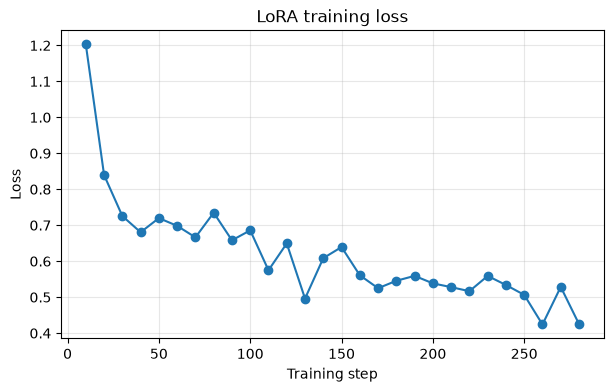

In [7]:
steps = [point["step"] for point in training_log["loss_points"]]
losses = [point["loss"] for point in training_log["loss_points"]]
plt.figure(figsize=(7, 4))
plt.plot(steps, losses, marker="o")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("LoRA training loss")
plt.grid(True, alpha=0.3)
plt.show()


## Part D: Re-evaluate

Same 50 problems, same prompt, same greedy decoding, same extraction rule, same harness. The only change is the LoRA adapter.


In [8]:
model.eval()
if hasattr(model, "gradient_checkpointing_disable"):
    model.gradient_checkpointing_disable()
model.config.use_cache = True

finetuned_path = os.path.join(RESULTS_DIR, "finetuned.json")
finetuned_rows = evaluate(eval_problems, finetuned_path)
print("saved", finetuned_path)


01/50 task 11 -> runs_fails


02/50 task 12 -> passes


03/50 task 13 -> runs_fails


04/50 task 14 -> runs_fails


05/50 task 15 -> runs_fails


06/50 task 16 -> runs_fails


... (42 outputs left out)

48/50 task 58 -> runs_fails


49/50 task 59 -> runs_fails


50/50 task 60 -> runs_fails


evaluation finished in 2.7 minutes
No function: 0
Runs, fails tests: 45
Passes: 5
Pass rate: 5/50
saved results/finetuned.json


In [9]:
with open(os.path.join(RESULTS_DIR, "baseline.json"), encoding="utf-8") as handle:
    baseline_rows = json.load(handle)
with open(os.path.join(RESULTS_DIR, "finetuned.json"), encoding="utf-8") as handle:
    finetuned_rows = json.load(handle)

base_counts = count_buckets(baseline_rows)
finetuned_counts = count_buckets(finetuned_rows)

header = f"{'':12} {'No function':>14} {'Runs, fails tests':>20} {'Passes':>8}"
print(header)
print(
    f"{'Base':12} {base_counts['no_function']:14d} "
    f"{base_counts['runs_fails']:20d} {base_counts['passes']:8d}"
)
print(
    f"{'Fine-tuned':12} {finetuned_counts['no_function']:14d} "
    f"{finetuned_counts['runs_fails']:20d} {finetuned_counts['passes']:8d}"
)
print()
print(f"Base pass rate: {base_counts['passes']}/50")
print(f"Fine-tuned pass rate: {finetuned_counts['passes']}/50")


                No function    Runs, fails tests   Passes
Base                      0                   47        3
Fine-tuned                0                   45        5

Base pass rate: 3/50
Fine-tuned pass rate: 5/50


## Part E: Examples from the recorded results

The two prints below are chosen by the code from the saved generations. The first is a problem that moved from "no function" to "passes", if one exists. The second stayed in "runs, fails tests" both times. The discussion after this cell uses these outputs.


In [10]:
def first_pair(source_bucket, dest_bucket):
    finetuned_by_id = {row["task_id"]: row for row in finetuned_rows}
    for row in baseline_rows:
        other = finetuned_by_id[row["task_id"]]
        if row["bucket"] == source_bucket and other["bucket"] == dest_bucket:
            return row, other
    return None, None


def print_move_table():
    finetuned_by_id = {row["task_id"]: row for row in finetuned_rows}
    print("Rows are the base bucket. Columns are the fine-tuned bucket.")
    header = f"{'':22}" + "".join(f"{BUCKET_LABELS[name]:>20}" for name in BUCKETS)
    print(header)
    for source in BUCKETS:
        counts = []
        for dest in BUCKETS:
            count = 0
            for row in baseline_rows:
                other = finetuned_by_id[row["task_id"]]
                if row["bucket"] == source and other["bucket"] == dest:
                    count += 1
            counts.append(count)
        line = f"{BUCKET_LABELS[source]:22}" + "".join(f"{count:20d}" for count in counts)
        print(line)


def print_pair(title, pair):
    print()
    print("=" * 70)
    print(title)
    print("=" * 70)
    base_row, tuned_row = pair
    if base_row is None:
        print("No problem matched this move.")
        return
    print("task_id:", base_row["task_id"])
    print("problem:", base_row["text"])
    print("tests:", base_row["test_list"])
    print()
    print("--- base output ---")
    print(base_row["generation"])
    print()
    print("--- fine-tuned output ---")
    print(tuned_row["generation"])
    print()
    print("base bucket:", base_row["bucket"])
    print("fine-tuned bucket:", tuned_row["bucket"])


print_move_table()
print_pair('Moved from "no function" to "passes"', first_pair("no_function", "passes"))
print_pair('Stayed in "runs, fails tests"', first_pair("runs_fails", "runs_fails"))


Rows are the base bucket. Columns are the fine-tuned bucket.
                               No function   Runs, fails tests              Passes
No function                              0                   0                   0
Runs, fails tests                        0                  44                   3
Passes                                   0                   1                   2

Moved from "no function" to "passes"
No problem matched this move.

Stayed in "runs, fails tests"
task_id: 11
problem: Write a python function to remove first and last occurrence of a given character from the string.
tests: ['assert remove_Occ("hello","l") == "heo"', 'assert remove_Occ("abcda","a") == "bcd"', 'assert remove_Occ("PHP","P") == "H"']

--- base output ---
Here is a Python function that removes the first and last occurrence of a given character from a string:

```python
def remove_first_last_occurrence(string, char):
    # Remove first occurrence
    first_occurrence_index = string.find(

### 1. Where did the improvement come from?

The pass rate went from 3/50 to 5/50. The "no function" count stayed at 0 both times. "Runs, fails tests" went from 47 to 45, and "passes" went from 3 to 5. The failure bucket shrank by 2 and the pass bucket grew by 2, so those two changes are the same size.

The move table is a little more detailed than the totals. Three problems moved from "runs, fails tests" into "passes" (tasks 17, 25, and 34). One problem moved the other way (task 37). Two problems passed both times, and 44 failed both times. No problem started in "no function."

Fine-tuning did not teach the model to begin writing functions. It already wrote one on every problem. The change is a small shift among answers that already ran: three more tests started passing, and one that used to pass stopped passing.


### 2. Format or ability?

This run mostly made the model better at the form of an MBPP answer. It did not make it a much better programmer.

The base model already followed "write a function." On these 50 problems it produced a `def` every time, usually after a short tutorial. The hidden tests do not call whatever name the model feels like using. They call one specific name, such as `square_perimeter` or `remove_Occ`, and that name is not in the prompt.

Task 17 is the clearest case. The base function returns `4 * side`, which is the right perimeter of a square, but the name is `find_square_perimeter`. The tests call `square_perimeter`, so it fails. The fine-tuned function is the same formula under the name `square_perimeter`, so it passes. The math was already there. The name changed.

Across all 50 problems, the test's function name shows up in 5 base answers and 9 fine-tuned answers. Passes only moved from 3 to 5. Task 37 also went backwards: the base code sorted numbers and strings the way the test wants, and the fine-tuned code sorts them in the wrong order. A model that gains two passes and loses one is only a little better at the actual problems. The clearer change is that its answers look more like the short training solutions, including the function names.


### 3. One example of each

There is no problem that moved from "no function" to "passes." The cell above prints "No problem matched this move," because both runs put all 50 problems in the other two buckets.

The clearest problem that did start passing is task 17: "Write a function to find the perimeter of a square." The tests are `square_perimeter(10)==40`, `square_perimeter(5)==20`, and `square_perimeter(4)==16`.

Base output (it keeps going with an example and then repeats itself; this is the function):

```python
def find_square_perimeter(side_length):
    perimeter = 4 * side_length
    return perimeter
```

Fine-tuned output:

```python
def square_perimeter(side):
  perimeter = 4 * side
  return perimeter
```

What changed is the name and the length of the answer. The base model explained the idea and picked its own name. The fine-tuned model stopped after a short function and used the name the tests call. The calculation was already correct.

The problem that stayed in "runs, fails tests" is task 11, printed in full in the cell above. The tests call `remove_Occ("hello","l")` and expect `"heo"`. The base model wrote `remove_first_last_occurrence`, which does remove the first and the last copy of the character, but under the wrong name. The fine-tuned model wrote `remove_char` and deleted the first character twice, which is a different task. Fine-tuning did not install the name `remove_Occ`, and it did not keep the first-and-last behavior.


### 4. What would you do with another hour?

I would put the function name into the prompt. For task 17 the added line would be "Name the function square_perimeter." I would expect "passes" to grow and "runs, fails tests" to shrink.

That is the bucket that is stuck, and task 17 shows why. The model already had a correct function and still failed, because the tests call a name the instruction never states. Only 9 of the 50 fine-tuned answers used the name the tests call. Another epoch on the same prompt would keep training the model to guess that name from the English sentence. The loss was still falling at the end (about 0.42), so more steps might help a little, but the examples say the missing name is the bigger gap.


## Before and after report

The fine-tuned pass rate on the fixed 50 test problems went from 3/50 to 5/50. Training took 21.0 minutes and updated 4,358,144 of 1,548,072,448 parameters, which is 0.28% of the model.

Before training, the 50 problems split into 0 with no function, 47 that ran and failed the tests, and 3 that passed. After training, the split was 0, 45, and 5. "No function" did not move. The two problems that left "runs, fails tests" are the same two that arrived in "passes." Under that total, three problems newly passed (tasks 17, 25, and 34) and one old pass failed (task 37), which is a net gain of two.

The base model was already willing to write a function. Every one of the 50 greedy completions contained a `def`. Many of those functions were wrapped in a short lesson and used a name the model invented. The MBPP tests ignore that name. They call one fixed name that is not written in the instruction, then check the return value.

That is why I read this result as a format change with a small ability change, not as the model becoming a strong programmer. On task 17 the base answer already computed the perimeter as four times the side. It failed only because the function was called `find_square_perimeter` instead of `square_perimeter`. After fine-tuning, the same formula was saved under the test's name, and the answer stopped at the function instead of continuing into an explanation. The test's function name appears in 5 base answers and 9 fine-tuned answers, which matches a model imitating the training solutions more closely.

The pass count only moved by two problems, and it was not pure progress. Task 37 passed before training and failed after it. The base code split the mixed list into numbers and strings, sorted each group, and concatenated them, which is what the test checks. The fine-tuned code sorts with a key that puts the strings first. So the adapter can also replace a working solution with a different one. On task 11, which failed both times, the base function removed the first and last occurrence of a character and the fine-tuned function removed the first occurrence twice. Neither used the name `remove_Occ`. Fine-tuning did not repair that problem.

A jump from 3 passes to 5 passes, with "no function" stuck at zero, is a real result for a 1.5B base model, 374 examples, and three epochs. The model learned to answer in a shorter, more MBPP-like shape. It did not learn to solve most of these held-out problems.
